In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

In [13]:
# Load the dataset
data = pd.read_csv('Earthquake_Warning_Datasets.csv')
print(data.head())

                       time   latitude   longitude      depth   mag magType  \
0  2022-08-23T02:37:54.740Z  36.044998 -120.609001   4.360000  0.78      md   
1  2022-08-23T02:30:13.850Z  19.181833 -155.353668  28.360001  2.30      ml   
2  2022-08-23T02:27:52.390Z  33.846833 -116.873667  14.750000  0.94      ml   
3  2022-08-23T02:15:47.520Z  35.674000 -117.441500   1.060000  1.10      ml   
4  2022-08-23T02:02:56.400Z  19.189167 -155.510666  35.779999  2.20      ml   

    nst    gap     dmin   rms net          id                   updated  \
0   8.0  205.0  0.02593  0.06  nc  nc73770880  2022-08-23T02:54:12.636Z   
1  43.0  183.0      NaN  0.13  hv  hv73118202  2022-08-23T02:35:43.770Z   
2  30.0   49.0  0.11590  0.19  ci  ci40330104  2022-08-23T02:31:24.156Z   
3  11.0  127.0  0.16140  0.22  ci  ci40330096  2022-08-23T02:19:17.881Z   
4  47.0   90.0      NaN  0.11  hv  hv73118182  2022-08-23T02:08:26.150Z   

                            place  horizontalError  depthError  magError  

In [14]:
# Drop unwanted columns
data.drop(columns=['id', 'updated', 'place', 'time'], inplace=True)

# Handle missing and infinite values
data.fillna(data.mean(), inplace=True)  # Impute missing values with mean

# Create an instance of LabelEncoder for each column
label_encoder_label = LabelEncoder()
label_encoder_magType = LabelEncoder()
label_encoder_net = LabelEncoder()

# Apply the label encoder to each column
data['Label'] = label_encoder_label.fit_transform(data['Label'])
data['magType'] = label_encoder_magType.fit_transform(data['magType'])
data['net'] = label_encoder_net.fit_transform(data['net'])

# Separate features (X) and target (y)
X = data.drop(columns=['Label'])
y = data['Label']


# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [15]:
# Split the data
print("Total records found in dataset = "+str(X.shape[0]))
print("Total features found in dataset= "+str(X.shape[1]))
print("80% dataset for training : "+str(X_train.shape[0]))
print("20% dataset for testing  : "+str(X_test.shape[0]))

Total records found in dataset = 8851
Total features found in dataset= 14
80% dataset for training : 6195
20% dataset for testing  : 2656


In [16]:
# Function to calculate all metrics
def calculateMetrics(algorithm, testY, predict):
    p = precision_score(testY, predict, average='macro') * 100
    r = recall_score(testY, predict, average='macro') * 100
    f = f1_score(testY, predict, average='macro') * 100
    a = accuracy_score(testY, predict) * 100
    print(algorithm + " Accuracy  : " + str(a))
    print(algorithm + " Precision : " + str(p))
    print(algorithm + " Recall    : " + str(r))
    print(algorithm + " FSCORE    : " + str(f))
    conf_matrix = confusion_matrix(testY, predict)
    #fig, axs = plt.subplots(1, 2, figsize=(10, 3))
    labels = ['warning', 'explosion']
    ax = sns.heatmap(conf_matrix, xticklabels=labels, yticklabels=labels, annot=True, cmap="viridis", fmt="g")
    ax.set_ylim([0, len(labels)])
    ax.set_title(algorithm + " Confusion matrix")


Training KNN model...
KNN Accuracy  : 94.31475903614458
KNN Precision : 91.77381659908343
KNN Recall    : 93.37781623853768
KNN FSCORE    : 92.53450262810243


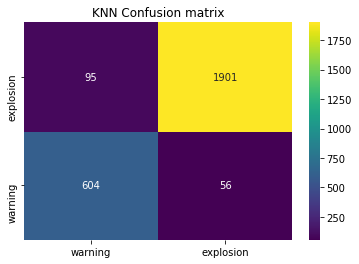

In [17]:
# Create models dictionary
models = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Train and evaluate KNN model
print("Training KNN model...")
knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)
knn_y_pred = knn_model.predict(X_test)

# KNN Confusion Matrix
calculateMetrics("KNN", y_test, knn_y_pred)

Training SVM model...
SVM Accuracy  : 87.19879518072288
SVM Precision : 78.65397461589848
SVM Recall    : 85.34326815401843
SVM FSCORE    : 81.18012676071602


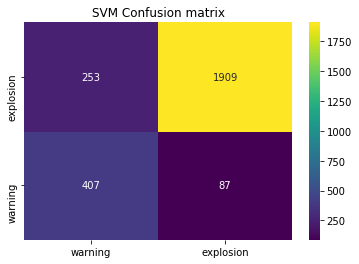

In [18]:
# Train and evaluate SVM
print("Training SVM model...")
svm_model = SVC()
svm_model.fit(X_train, y_train)
svm_y_pred = svm_model.predict(X_test)

# SVM Confusion Matrix
calculateMetrics("SVM", svm_y_pred, y_test)


Training Random Forest model...
Random Forest Accuracy: 0.9789156626506024
Random Forest Accuracy  : 97.89156626506023
Random Forest Precision : 97.27880002429102
Random Forest Recall    : 97.08835341365462
Random Forest FSCORE    : 97.18309005566547


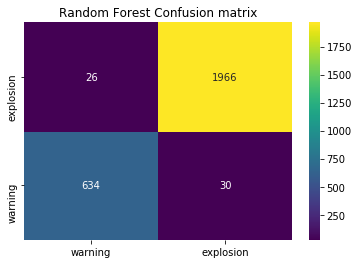

In [19]:
# Train and evaluate Random Forest
print("Training Random Forest model...")
global rf_model
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
rf_y_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred)
print(f"Random Forest Accuracy: {rf_accuracy}")

# Random Forest Confusion Matrix
calculateMetrics("Random Forest", rf_y_pred, y_test)


Training Decision Tree model...
Decision Tree Accuracy: 0.9615963855421686
Decision Tree Accuracy  : 96.15963855421687
Decision Tree Precision : 94.96022347725754
Decision Tree Recall    : 94.77911646586345
Decision Tree FSCORE    : 94.86919974424785


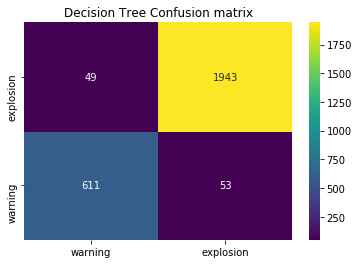

In [10]:
# Train and evaluate Decision Tree
print("Training Decision Tree model...")
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
dt_y_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_y_pred)
print(f"Decision Tree Accuracy: {dt_accuracy}")

# Decision Tree Confusion Matrix
calculateMetrics("Decision Tree", dt_y_pred, y_test)

In [10]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
global rf_model
# Initialize LabelEncoders for categorical columns if needed
label_encoder_magType = LabelEncoder()
label_encoder_net = LabelEncoder()
label_encoder_magType.fit(['mb', 'ml', 'ms', 'mw'])  # Example categories for magType
label_encoder_net.fit(['us', 'ci', 'hv', 'nc', 'sc'])  # Example categories for net

# Collect user input
user_input = pd.DataFrame({
    'latitude': [float(input("Enter latitude: "))], 
    'longitude': [float(input("Enter longitude: "))], 
    'depth': [float(input("Enter depth: "))], 
    'mag': [float(input("Enter magnitude (mag): "))], 
    'magType': [input("Enter magType (e.g., mb, ml, ms, mw): ")],  # Categorical column
    'nst': [int(input("Enter number of stations (nst): "))],
    'gap': [float(input("Enter gap: "))],
    'dmin': [float(input("Enter minimum distance (dmin): "))],
    'rms': [float(input("Enter RMS: "))],
    'net': [input("Enter network (net) (e.g., us, ci, hv, nc, sc): ")],  # Categorical column
    'horizontalError': [float(input("Enter horizontal error: "))],
    'depthError': [float(input("Enter depth error: "))],
    'magError': [float(input("Enter magnitude error (magError): "))],
    'magNst': [int(input("Enter magNst: "))]
})

# Encode categorical columns using the pre-fitted encoders
user_input['magType'] = label_encoder_magType.transform(user_input['magType'])
user_input['net'] = label_encoder_net.transform(user_input['net'])

print("Processed user input:")
print(user_input)


# Make the prediction
predicted_label = rf_model.predict(user_input)
#Label = ['Earthquake', 'Explosion']

# Output the predicted label
print("Predicted Label:", predicted_label)


Enter latitude: 567890jkl;


ValueError: could not convert string to float: '567890jkl;'

In [11]:
from flask import Flask, render_template, request
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import threading
from IPython.display import display, HTML

# Create the Flask app
app = Flask(__name__, template_folder="templates")

# Pre-fit LabelEncoders for categorical columns
label_encoder_magType = LabelEncoder()
label_encoder_magType.fit(['mb', 'ml', 'ms', 'mw'])
label_encoder_net = LabelEncoder()
label_encoder_net.fit(['us', 'ci', 'hv', 'nc', 'sc'])

@app.route('/')
def index():
    return render_template('index.html')

@app.route('/predict', methods=['POST'])
def predict():
    # Get user input from form
    latitude = float(request.form['latitude'])
    longitude = float(request.form['longitude'])
    depth = float(request.form['depth'])
    mag = float(request.form['mag'])
    magType = request.form['magType']
    nst = int(request.form['nst'])
    gap = float(request.form['gap'])
    dmin = float(request.form['dmin'])
    rms = float(request.form['rms'])
    net = request.form['net']
    horizontalError = float(request.form['horizontalError'])
    depthError = float(request.form['depthError'])
    magError = float(request.form['magError'])
    magNst = int(request.form['magNst'])

    # Convert input values into a DataFrame
    user_input = pd.DataFrame([{
        'latitude': latitude,
        'longitude': longitude,
        'depth': depth,
        'mag': mag,
        'magType': magType,
        'nst': nst,
        'gap': gap,
        'dmin': dmin,
        'rms': rms,
        'net': net,
        'horizontalError': horizontalError,
        'depthError': depthError,
        'magError': magError,
        'magNst': magNst
    }])

    # Encode categorical columns
    user_input['magType'] = label_encoder_magType.transform(
        user_input['magType'].apply(lambda x: x if x in label_encoder_magType.classes_ else 'mb'))  # Default to 'mb'
    user_input['net'] = label_encoder_net.transform(
        user_input['net'].apply(lambda x: x if x in label_encoder_net.classes_ else 'us'))  # Default to 'us'

    # Perform prediction using the trained model
    # Assume rf_model is loaded globally
    predicted_label = rf_model.predict(user_input)

    # Map prediction output to corresponding labels
    if predicted_label == 0:
        event_label = "Earthquake"
    else:
        event_label = "Explosion"

    # Render the result page with the prediction
    return render_template('result.html', event_label=event_label)

# Run the Flask app in a thread to allow Jupyter notebook execution
def run_flask_app():
    app.run(debug=True, use_reloader=False, threaded=True)

# Start the Flask app in a new thread
thread = threading.Thread(target=run_flask_app)
thread.start()

# Display the URL where the Flask app is running
display(HTML("<a href='http://127.0.0.1:5000' target='_blank'>Click here to access the Flask app</a>"))


 * Serving Flask app '__main__' (lazy loading)
 * Environment: production
   Use a production WSGI server instead.
 * Debug mode: on


 * Running on http://127.0.0.1:5000/ (Press CTRL+C to quit)
127.0.0.1 - - [10/Jan/2025 05:31:43] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [10/Jan/2025 05:32:23] "POST /predict HTTP/1.1" 200 -


In [22]:
from flask import Flask, render_template, request
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import threading
from IPython.display import display, HTML

# Create the Flask app
app = Flask(__name__, template_folder="templates")

# Pre-fit LabelEncoders for categorical columns
label_encoder_magType = LabelEncoder()
label_encoder_magType.fit(['mb', 'ml', 'ms', 'mw'])
label_encoder_net = LabelEncoder()
label_encoder_net.fit(['us', 'ci', 'hv', 'nc', 'sc'])

def calculate_area_affected(magnitude):
    # Example formula: Area = 10^(0.5 * mag + 2) (this is an illustrative formula)
    return 10 ** (0.5 * magnitude + 2)

@app.route('/')
def index():
    
    return render_template('index.html')

@app.route('/predict', methods=['POST'])
def predict():
    # Get user input from form
    latitude = float(request.form['latitude'])
    longitude = float(request.form['longitude'])
    depth = float(request.form['depth'])
    mag = float(request.form['mag'])
    magType = request.form['magType']
    nst = int(request.form['nst'])
    gap = float(request.form['gap'])
    dmin = float(request.form['dmin'])
    rms = float(request.form['rms'])
    net = request.form['net']
    horizontalError = float(request.form['horizontalError'])
    depthError = float(request.form['depthError'])
    magError = float(request.form['magError'])
    magNst = int(request.form['magNst'])

    # Convert input values into a DataFrame
    user_input = pd.DataFrame([{
        'latitude': latitude,
        'longitude': longitude,
        'depth': depth,
        'mag': mag,
        'magType': magType,
        'nst': nst,
        'gap': gap,
        'dmin': dmin,
        'rms': rms,
        'net': net,
        'horizontalError': horizontalError,
        'depthError': depthError,
        'magError': magError,
        'magNst': magNst
    }])

    # Encode categorical columns
    user_input['magType'] = label_encoder_magType.transform(
        user_input['magType'].apply(lambda x: x if x in label_encoder_magType.classes_ else 'mb'))  # Default to 'mb'
    user_input['net'] = label_encoder_net.transform(
        user_input['net'].apply(lambda x: x if x in label_encoder_net.classes_ else 'us'))  # Default to 'us'

    # Perform prediction using the trained model
    # Assume rf_model is loaded globally
    predicted_label = rf_model.predict(user_input)

    # Map prediction output to corresponding labels
    event_label = "Earthquake" if predicted_label == 0 else "Explosion"

    # Calculate the area affected
    area_affected = calculate_area_affected(mag)
    print(f"Calculated area affected: {area_affected}")
    # Render the result page with the prediction and area affected
    return render_template('result.html', event_label=event_label)
    #return render_template('result.html', event_label=event_label,area_affected=f"{area_affected:.2f}")

# Run the Flask app in a thread to allow Jupyter notebook execution
def run_flask_app():
    app.run(debug=True, use_reloader=False, threaded=True)

# Start the Flask app in a new thread
thread = threading.Thread(target=run_flask_app)
thread.start()

# Display the URL where the Flask app is running
display(HTML("<a href='http://127.0.0.1:5000' target='_blank'>Click here to access the Flask app</a>"))


 * Serving Flask app '__main__' (lazy loading)


 * Environment: production
   Use a production WSGI server instead.
 * Debug mode: on


 * Running on http://127.0.0.1:5000/ (Press CTRL+C to quit)
127.0.0.1 - - [10/Jan/2025 06:47:02] "GET / HTTP/1.1" 200 -
